# Лабораторная работа №1: регрессия
## 1. Знакомство с данными

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")
RANDOM_STATE = 42

In [15]:
URL_RED = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
URL_WHITE = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

df = pd.read_csv(URL_RED, sep=";")
print("Размер:", df.shape)
df.head()

Размер: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Таблица включает информацию о 1599 красных винах. Для каждого вина известны 11 физико-химических характеристик: нелетучие и летучие кислоты, лимонная кислота, сахар, соль, свободный диоксид серы, общий диоксид серы, плотность, pH, сульфаты, крепость алкоголя. Целевая переменная — quality, оценка качества дегустаторами по шкале от 0 до 10. Задача — по признакам предсказать quality, это задача регрессии.

In [16]:
df.info()
print("Пропуски по столбцам:")
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB
Пропуски по столбцам:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0


### Вывод по типам данных и пропускам

Таблица не содержит пропусков: во всех 12 столбцах по 1599 непустых значений. Значит, заполнять пропуски или удалять строки не требуется.

Все 11 физико-химических признаков хранятся в формате `float64`, а целевая переменная `quality` — в формате `int64`. Категориальных признаков нет, поэтому кодирование не нужно: данные можно сразу использовать для обучения моделей.

Оценки `quality` дискретные (целые числа), но по условию задачи решается регрессия, поэтому модель будет предсказывать непрерывное значение.

In [17]:
n_dup = df.duplicated().sum()
print("Строк дубликатов:", n_dup)
print("Доля от всех строк:", round(n_dup / len(df), 3))

Строк дубликатов: 240
Доля от всех строк: 0.15


### Вывод по дубликатам

В датасете 240 строк (15% данных) полностью повторяют уже встречавшиеся строки. Возможно, это разные вина с одинаковыми результатами измерений, но для модели они неотличимы.

Если не удалить дубликаты, одно и то же вино может оказаться и в train, и в test. Тогда модель будет проверяться на данных, которые она уже видела, и ошибка выйдет меньше, чем на самом деле. Поэтому дубликаты удаляю до разбиения на выборки.

In [18]:
df = df.drop_duplicates().reset_index(drop=True)
print("Размер после удаления дубликатов:", df.shape)

Размер после удаления дубликатов: (1359, 12)


После удаления дубликатов осталось 1359 вин.

In [19]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1359.0,8.310596,1.736990,4.60000,7.1000,7.9000,9.20000,15.90000
volatile acidity,1359.0,0.529478,0.183031,0.12000,0.3900,0.5200,0.64000,1.58000
citric acid,1359.0,0.272333,0.195537,0.00000,0.0900,0.2600,0.43000,1.00000
residual sugar,1359.0,2.523400,1.352314,0.90000,1.9000,2.2000,2.60000,15.50000
chlorides,1359.0,0.088124,0.049377,0.01200,0.0700,0.0790,0.09100,0.61100
free sulfur dioxide,1359.0,15.893304,10.447270,1.00000,7.0000,14.0000,21.00000,72.00000
total sulfur dioxide,1359.0,46.825975,33.408946,6.00000,22.0000,38.0000,63.00000,289.00000
density,1359.0,0.996709,0.001869,0.99007,0.9956,0.9967,0.99782,1.00369
pH,1359.0,3.309787,0.155036,2.74000,3.2100,3.3100,3.40000,4.01000
sulphates,1359.0,0.658705,0.170667,0.33000,0.5500,0.6200,0.73000,2.00000


### Вывод по описательной статистике

Признаки измерены в разных единицах и сильно различаются по масштабу: std у density около 0,0019, а у total sulfur dioxide около 33,41. Поэтому для линейной регрессии признаки нужно стандартизировать, иначе её коэффициенты нельзя сравнивать.

У нескольких признаков есть выбросы — максимум сильно больше 75%-квантиля: chlorides (примерно в 6,7 раз), residual sugar (примерно в 6 раз), total sulfur dioxide (примерно в 4,6 раза), free sulfur dioxide (примерно в 3,4 раза). Выбросы сильнее всего влияют на линейную регрессию, потому что она минимизирует квадраты ошибок и далёкие точки сильно на неё влияют. Удалять их не стоит, так как это могут быть настоящие вина, которые могут встретиться в тестовых данных.

Целевая переменная quality: среднее 5,62, std 0,82. Значит, baseline (предсказание среднего) даст RMSE около 0,82, это хуже порога 0,70.

Количество вин с каждой оценкой:
quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64

Доли:
quality
3    0.007
4    0.039
5    0.425
6    0.394
7    0.123
8    0.013
Name: count, dtype: float64


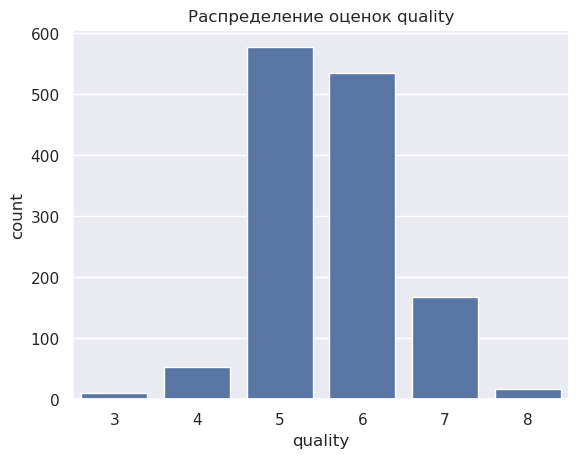

Среднее quality: 5.623
Стандартное отклонение quality: 0.824


In [20]:
counts = df["quality"].value_counts().sort_index()
print("Количество вин с каждой оценкой:")
print(counts)
print()
print("Доли:")
print((counts / len(df)).round(3))

sns.countplot(x="quality", data=df)
plt.title("Распределение оценок quality")
plt.show()

print("Среднее quality:", round(df["quality"].mean(), 3))
print("Стандартное отклонение quality:", round(df["quality"].std(), 3))

### Вывод по целевой переменной

Оценки распределены неравномерно: 5 и 6 вместе составляют около 82% данных, а оценки 3 и 8 — около 2%. Оценок 0, 1, 2, 9, 10 в данных нет совсем.

Из-за этого модель будет хорошо предсказывать вина с оценками 5 и 6, а для редких оценок будет ошибаться сильнее: она будет сдвигать предсказания к среднему. На таких винах модель будет ошибаться сильно, а в RMSE ошибки возводятся в квадрат, поэтому большие ошибки сильно увеличат итоговую метрику.

## 2. Связь признаков с quality

volatile acidity       -0.395
density                -0.184
total sulfur dioxide   -0.178
chlorides              -0.131
pH                     -0.055
free sulfur dioxide    -0.050
residual sugar          0.014
fixed acidity           0.119
citric acid             0.228
sulphates               0.249
alcohol                 0.480
Name: quality, dtype: float64


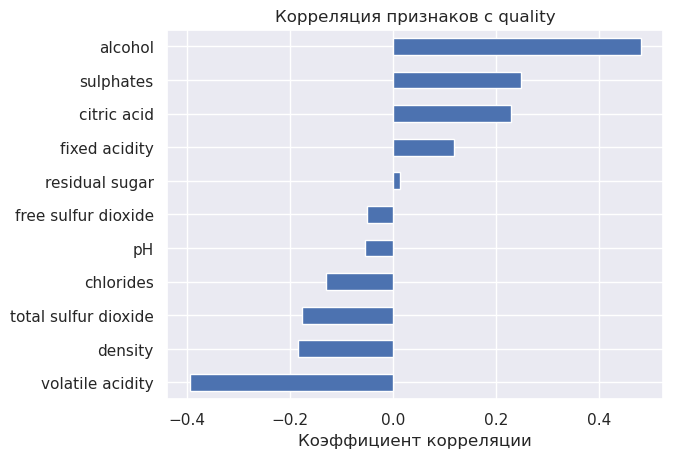

In [21]:
corr_with_quality = df.corr()["quality"].drop("quality").sort_values()
print(corr_with_quality.round(3))

corr_with_quality.plot(kind="barh")
plt.title("Корреляция признаков с quality")
plt.xlabel("Коэффициент корреляции")
plt.show()

### Выводы по корреляции данных с quality

Параметр alcohol имеет самую высокую корреляцию с качеством, соответственно вина с высоким показателем данной переменной в среднем получают оценку выше.

Параметр volatile acidity имеет самую сильную отрицательную корреляцию, следовательно вина с низким показателем данного параметра в среднем получают более высокую оценку.

Корреляция с параметром residual sugar близка к 0, то есть линейной связи нет.

Даже у лучшего признака корреляция около 0.5, поэтому по одному признаку оценку не предсказать - модели нужно учитывать признаки вместе.

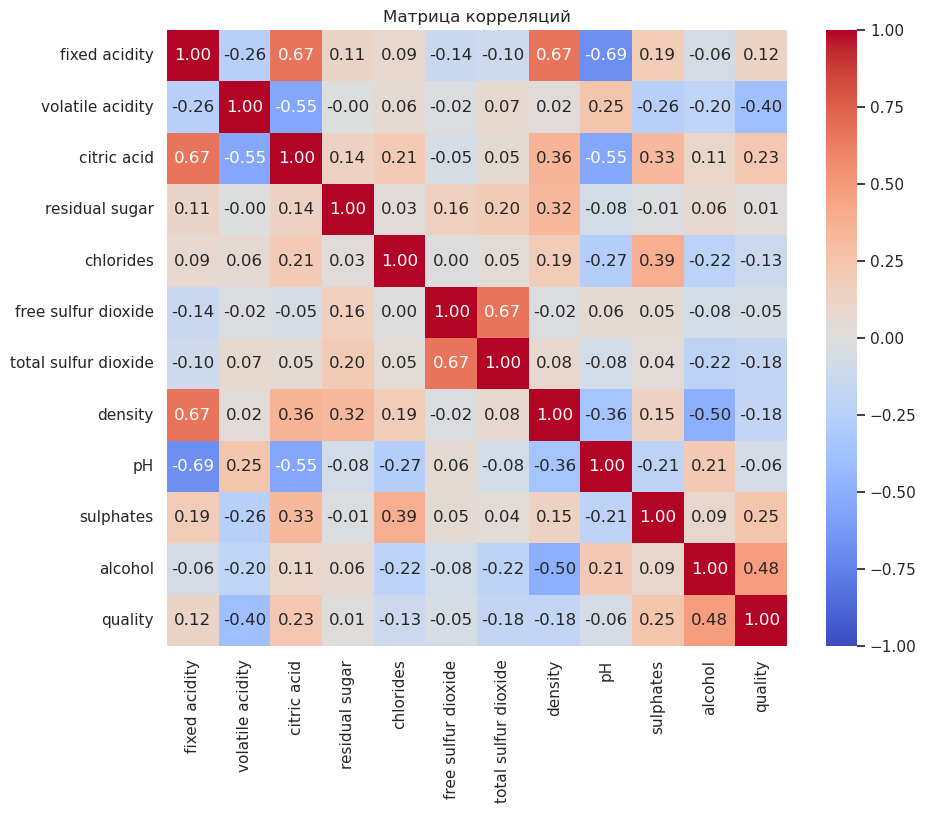

In [22]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Матрица корреляций")
plt.show()

### Выводы по корреляции признаков между собой

Самая высокая корреляция (около 0,67) замечена между fixed acidity и citric acid, fixed acidity и density, а также free sulfur dioxide и total sulfur dioxide. Для SO₂ и для кислот это логично: свободный SO₂ — часть общего, а лимонная кислота входит в нелетучие кислоты. Самая сильная отрицательная корреляция у pH и fixed acidity (−0,69), что тоже логично: чем больше кислот, тем ниже pH.

Сильно связанные признаки несут похожую информацию. Из-за этого коэффициенты линейной регрессии у них могут быть неустойчивыми, а важность в деревьях будет делиться между ними.Нужно это учесть в feature importance.

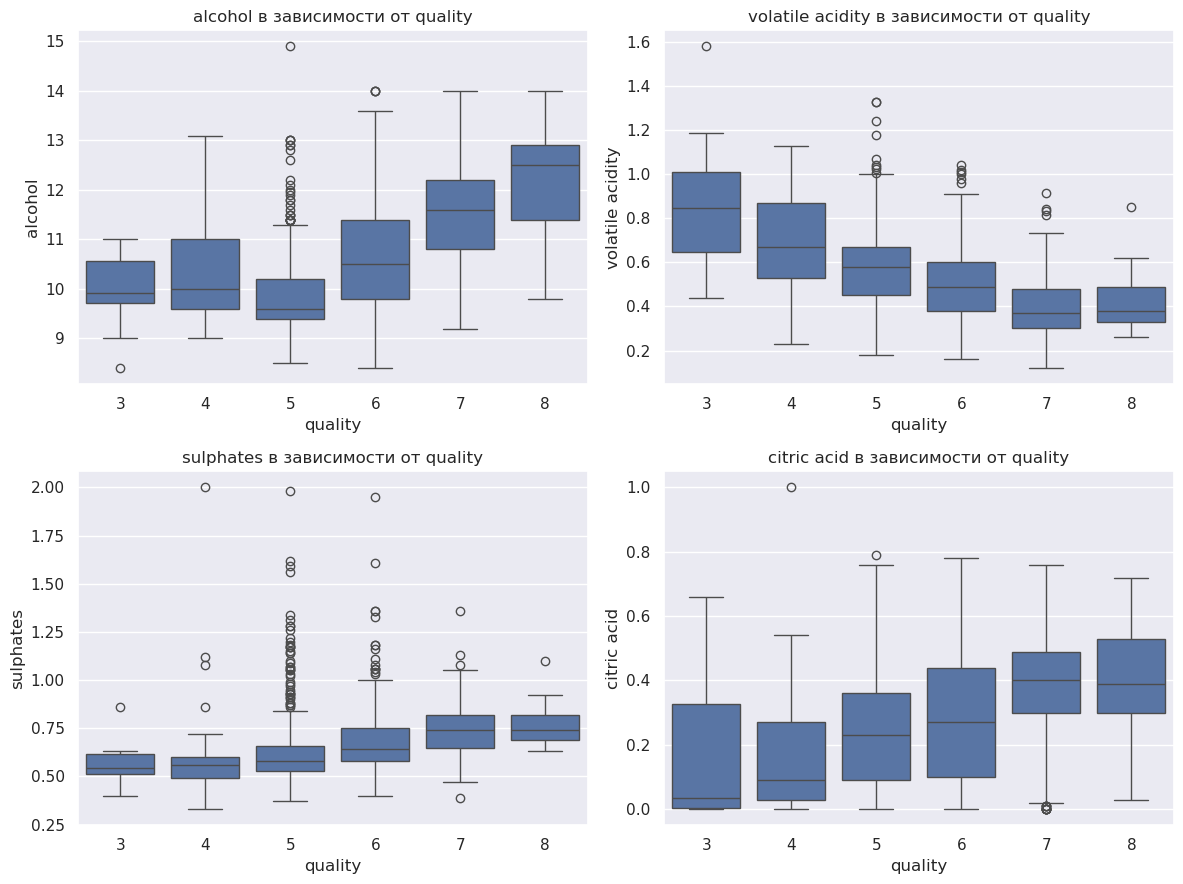

In [23]:
top_features = corr_with_quality.abs().sort_values(ascending=False).head(4).index

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    sns.boxplot(x="quality", y=feature, data=df, ax=axes[i])
    axes[i].set_title(f"{feature} в зависимости от quality")

plt.tight_layout()
plt.show()

### Выводы по boxplot

**alcohol:** С ростом оценки алкоголь в целом растёт, но не равномерно: у оценок 3–5 медиана почти одинаковая, а с 5 до 8 медиана заметно растёт. То есть алкоголь хорошо отличает хорошие вина (7–8) от средних, но почти не помогает различать плохие и средние.

**volatile acidity:** Медиана плавно падает с 3 по 7 оценки, а у 7 и 8 почти одинаковая. Это самая равномерная зависимость из четырёх.

**sulphates:** Медиана растёт в основном от 5 к 7, у оценок 3–4 и 7–8 почти не меняется. У оценок 5 и 6 много выбросов вверх, до 2,0.

**citric acid:** Медиана растёт от почти 0 у оценки 3 до 0,4 у оценок 7–8. Разброс у плохих вин очень большой: у оценки 3 ящик тянется от 0 до 0,33.

Ящики соседних оценок, особенно 5 и 6, сильно перекрываются на всех четырёх графиках.По одному признаку вина с соседними оценками не различить, что согласуется с умеренными корреляциями. Модели придётся учитывать признаки вместе, и нелинейные модели здесь могут помочь: например, алкоголь работает по-разному для плохих и хороших вин.

Для оценок 3 и 8 данных мало (около 10 и 17 вин), поэтому их ящики ненадёжны, и на таких винах модель, скорее всего, будет ошибаться сильнее.

## 3. Разбиение на train и test

In [24]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["quality"])
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("train:", X_train.shape)
print("test:", X_test.shape)

train: (1087, 11)
test: (272, 11)


In [25]:
dist = pd.DataFrame({
    "train": y_train.value_counts(normalize=True).sort_index(),
    "test": y_test.value_counts(normalize=True).sort_index(),
}).round(3)

dist

,train,test
quality,,
3,0.007,0.007
4,0.039,0.040
5,0.424,0.426
6,0.394,0.393
7,0.123,0.121
8,0.013,0.011


### Вывод по разбиению

Возьмём 80% данных на обучение и 20% на тест. Это нужно, чтобы модели хватило данных для обучения, а тест был достаточно большим для честной оценки.

random_state фиксирует, как перемешиваются данные перед разбиением, поэтому при каждом запуске разбиение одинаковое и результаты можно повторить.

stratify=y делает доли каждой оценки в train и test одинаковыми, что видно в таблице выше. Без этого редкие оценки 3 и 8 могли бы почти все попасть в одну часть.

Тестовую выборку используем только один раз в конце, чтобы не подогнать выбор модели под тест, иначе оценка качества будет завышенной.

### Baseline

In [26]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# Baseline: всегда предсказываем среднее quality по train
baseline_value = y_train.mean()
y_pred_baseline = np.full(len(y_test), baseline_value)

rmse_baseline = root_mean_squared_error(y_test, y_pred_baseline)
mae_baseline = mean_absolute_error(y_test, y_pred_baseline)

print("Константа (среднее по train):", round(baseline_value, 3))
print("RMSE:", round(rmse_baseline, 3))
print("MAE:", round(mae_baseline, 3))

Константа (среднее по train): 5.626
RMSE: 0.819
MAE: 0.692


### Вывод по baseline

В качестве baseline всем винам предсказываем одно число — среднее quality по train (5,626). Среднее выбрано, потому что для RMSE сумма квадратов ошибок будет минимальной. Считаем его по train, потому что данные из test модели пока недоступны.

MAE показывает средний модуль ошибок. У baseline MAE = 0.692, то есть в среднем он ошибается на 0.692 балла.

RMSE показывает квадратный корень из среднего квадратов ошибок. Это позволяет сильнее штрафовать большие ошибки. У baseline RMSE = 0,819, и он заметно больше MAE, значит, есть крупные промахи — на редких оценках. RMSE больше порога 0,70, поэтому одного среднего недостаточно: модели нужно использовать признаки, чтобы снизить ошибку.

## 4. Линейная регрессия

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

lin_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])
lin_model.fit(X_train, y_train)

y_pred_train_lin = lin_model.predict(X_train)
y_pred_lin = lin_model.predict(X_test)

rmse_lin = root_mean_squared_error(y_test, y_pred_lin)
mae_lin = mean_absolute_error(y_test, y_pred_lin)

print("RMSE на train:", round(root_mean_squared_error(y_train, y_pred_train_lin), 3))
print("RMSE на test: ", round(rmse_lin, 3))
print("MAE на test:  ", round(mae_lin, 3))
print("RMSE baseline:", round(rmse_baseline, 3))

RMSE на train: 0.66
RMSE на test:  0.652
MAE на test:   0.507
RMSE baseline: 0.819


### Вывод по качеству линейной регрессии

RMSE на test = 0,652, это на 20% лучше baseline (0,819), значит, модель извлекает из признаков полезную информацию. MAE = 0,507: в среднем модель ошибается на полбалла. Порог 0,70 на нашем тесте пройден, но запас небольшой, поэтому на скрытой выборке результат может оказаться хуже.

RMSE на train и test почти одинаковые (0,66 и 0,652), значит, переобучения нет. При этом ошибка остаётся большой, потому что линейная модель слишком простая (недообучена), а в данных зависимости нелинейные и вина с соседними оценками похожи друг на друга.

citric acid             0.014
density                -0.015
residual sugar         -0.021
fixed acidity           0.022
free sulfur dioxide     0.053
pH                     -0.056
total sulfur dioxide   -0.090
chlorides              -0.093
sulphates               0.148
volatile acidity       -0.187
alcohol                 0.310
dtype: float64


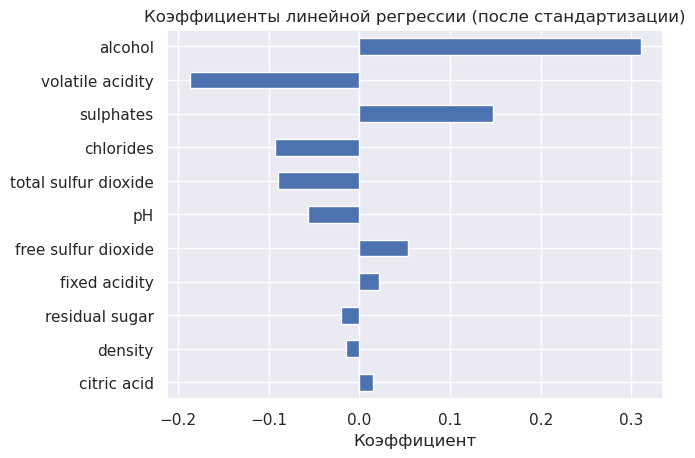

In [28]:
coefs = pd.Series(lin_model.named_steps["model"].coef_, index=X.columns)
coefs = coefs.sort_values(key=abs)   # сортируем по модулю

print(coefs.round(3))

coefs.plot(kind="barh")
plt.title("Коэффициенты линейной регрессии (после стандартизации)")
plt.xlabel("Коэффициент")
plt.show()

### Вывод по коэффициентам линейной регрессии

Признаки стандартизированы, поэтому коэффициенты можно сравнивать: каждый показывает, на сколько изменится предсказание, если признак вырастет на одно стандартное отклонение при неизменных остальных признаках.

Сильнее всего на предсказание влияют alcohol (0.310), volatile acidity (-0.187) и sulphates (0.148). Знаки совпадают с корреляцией.

У citric acid и density корреляция с quality заметная, а коэффициенты почти нулевые. Citric acid сильно связана с volatile acidity (−0,55) и fixed acidity (0,67), поэтому её полезная информация уже есть в этих признаках. Density связана с alcohol (−0,50), так как спирт легче воды, и когда алкоголь уже учтён в модели, плотность почти ничего не добавляет.

У free sulfur dioxide знак коэффициента противоположен знаку корреляции. Это связано с мультиколлинеарностью: он сильно коррелирует с total sulfur dioxide (0,67), и модель делит вклад между ними. Поэтому коэффициент неустойчивый, и делать по нему выводы о влиянии на качество нельзя.

In [29]:
raw_model = LinearRegression()
raw_model.fit(X_train, y_train)
raw_coefs = pd.Series(raw_model.coef_, index=X.columns)

comparison = pd.DataFrame({
    "без масштабирования": raw_coefs,
    "после стандартизации": coefs,
}).round(3)

y_pred_raw = raw_model.predict(X_test)
print("RMSE без масштабирования:", round(root_mean_squared_error(y_test, y_pred_raw), 3))
print("RMSE со стандартизацией: ", round(rmse_lin, 3))

comparison

RMSE без масштабирования: 0.652
RMSE со стандартизацией:  0.652


,без масштабирования,после стандартизации
alcohol,0.283,0.310
chlorides,-1.951,-0.093
citric acid,0.073,0.014
density,-7.922,-0.015
fixed acidity,0.012,0.022
free sulfur dioxide,0.005,0.053
pH,-0.356,-0.056
residual sugar,-0.015,-0.021
sulphates,0.872,0.148
total sulfur dioxide,-0.003,-0.090


### Вывод по масштабированию

Без масштабирования самым важным кажется density (коэффициент −7,922), но после стандартизации его коэффициент всего −0,015. Наоборот, у total sulfur dioxide сырой коэффициент −0,003, а после стандартизации −0,090.

Так происходит, потому что коэффициент без масштабирования показывает изменение предсказания при росте признака на одну единицу, а единицы у признаков разные.

На качество линейной регрессии масштабирование не влияет (RMSE 0,652 в обоих случаях), оно нужно только для того, чтобы коэффициенты можно было сравнивать между собой.

## 5. Случайный лес

Случайный лес состоит из множества решающих деревьев, каждое обучается на случайной подвыборке объектов. Итоговое предсказание — среднее предсказаний всех деревьев. Деревьям не важен масштаб признаков, поэтому стандартизация не нужна.

In [30]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
rf_model.fit(X_train, y_train)

y_pred_train_rf = rf_model.predict(X_train)
y_pred_rf = rf_model.predict(X_test)

rmse_rf = root_mean_squared_error(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)

print("RMSE на train:", round(root_mean_squared_error(y_train, y_pred_train_rf), 3))
print("RMSE на test: ", round(rmse_rf, 3))
print("MAE на test:  ", round(mae_rf, 3))
print()
print("RMSE линейной регрессии:", round(rmse_lin, 3))
print("RMSE baseline:          ", round(rmse_baseline, 3))

RMSE на train: 0.239
RMSE на test:  0.626
MAE на test:   0.48

RMSE линейной регрессии: 0.652
RMSE baseline:           0.819


### Вывод по качеству случайного леса

RMSE на test = 0,626, это на 24% лучше baseline и на 4% лучше линейной регрессии. MAE = 0,48. Порог 0,70 пройден с запасом 0,074.

RMSE на train (0,239) намного меньше, чем на test, потому что каждое дерево растёт до конца и запоминает свою подвыборку. Это переобучение отдельных деревьев, но на качество на test оно не повлияло: усреднение 300 разных деревьев гасит их случайные ошибки, и на test лес всё равно лучше линейной регрессии. Поэтому качество леса оцениваем только по test.

Лес лучше линейной регрессии, потому что деревья ловят нелинейные зависимости. Но улучшение небольшое, потому что оценки ставят люди, это шумная величина, а вина с соседними оценками очень похожи по признакам.

fixed acidity           0.047
free sulfur dioxide     0.047
citric acid             0.048
density                 0.052
residual sugar          0.056
pH                      0.058
chlorides               0.064
total sulfur dioxide    0.073
volatile acidity        0.140
sulphates               0.148
alcohol                 0.266
dtype: float64


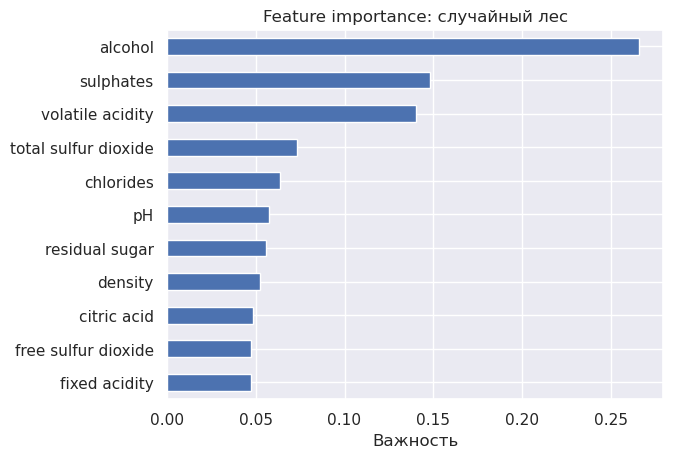

In [31]:
rf_importance = pd.Series(rf_model.feature_importances_, index=X.columns)
rf_importance = rf_importance.sort_values()

print(rf_importance.round(3))

rf_importance.plot(kind="barh")
plt.title("Feature importance: случайный лес")
plt.xlabel("Важность")
plt.show()

### Вывод по feature importance случайного леса

Самые важные признаки —  alcohol, sulphates и volatile acidity, вместе на них приходится больше половины всей важности. У остальных признаков важность примерно одинаковая, около 0,05-0,07.

Это совпадает с корреляцией из части 2. Отличие — citric acid: было на четвёртом месте, а стало третьей с конца.

С линейной регрессией тройка лидеров тоже совпадает. Citric acid и density, как и там, слабы, потому что их информация уже есть в других признаках.

У residual sugar корреляция с quality почти нулевая, но важность не меньше, чем у pH и density. Важность считается на train, а глубокие деревья подгоняются под шум и делают разбиения по любым признакам, поэтому даже бесполезный признак получает немного важности. Уверенно можно говорить только о трёх лидерах, которые сильно оторвались от остальных.

## 6. Градиентный бустинг

Градиентный бустинг строит деревья последовательно: начинает с константы (среднего), а каждое следующее неглубокое дерево обучается на ошибках предыдущих и с небольшим шагом добавляется к модели. Масштабирование, как и для леса, не нужно.

In [32]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(random_state=RANDOM_STATE)
gb_model.fit(X_train, y_train)

y_pred_train_gb = gb_model.predict(X_train)
y_pred_gb = gb_model.predict(X_test)

rmse_gb = root_mean_squared_error(y_test, y_pred_gb)
mae_gb = mean_absolute_error(y_test, y_pred_gb)

print("RMSE на train:", round(root_mean_squared_error(y_train, y_pred_train_gb), 3))
print("RMSE на test: ", round(rmse_gb, 3))
print("MAE на test:  ", round(mae_gb, 3))
print()
print("RMSE леса:              ", round(rmse_rf, 3))
print("RMSE линейной регрессии:", round(rmse_lin, 3))
print("RMSE baseline:          ", round(rmse_baseline, 3))

RMSE на train: 0.494
RMSE на test:  0.634
MAE на test:   0.496

RMSE леса:               0.626
RMSE линейной регрессии: 0.652
RMSE baseline:           0.819


### Вывод по качеству градиентного бустинга

RMSE на test = 0,634, это на 23% лучше baseline и лучше линейной регрессии (0,652), но чуть хуже леса (0,626). MAE = 0,496. Порог 0,70 пройден с запасом 0,066.

Разница с лесом всего 0,008, на тесте из 272 вин это почти шум, поэтому можно считать, что качество моделей практичемки одинаково. Лес мог оказаться чуть лучше, потому что бустинг использует параметры по умолчанию, а данные шумные (субъективность дегустаторов).

Разрыв между train и test меньше, чем у леса, потому что у бустинга деревья глубины 3, у каждого максимум 8 листьев, и запомнить отдельные вина они не могут. Лесу же деревья до конца позволяли почти выучить train.

                      Random Forest  Gradient Boosting
free sulfur dioxide           0.047              0.019
citric acid                   0.048              0.027
fixed acidity                 0.047              0.030
residual sugar                0.056              0.031
chlorides                     0.064              0.034
density                       0.052              0.036
pH                            0.058              0.048
total sulfur dioxide          0.073              0.067
sulphates                     0.148              0.171
volatile acidity              0.140              0.174
alcohol                       0.266              0.363


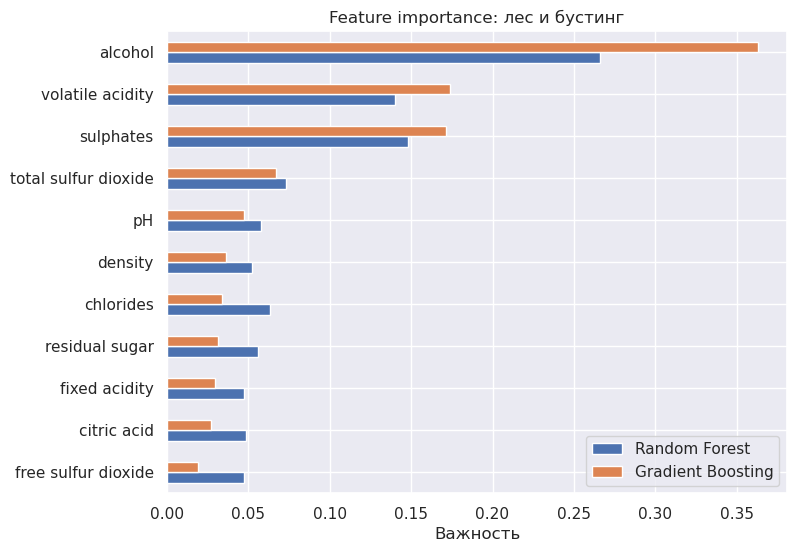

In [33]:
gb_importance = pd.Series(gb_model.feature_importances_, index=X.columns)

importance = pd.DataFrame({
    "Random Forest": rf_importance,
    "Gradient Boosting": gb_importance,
}).sort_values("Gradient Boosting")

print(importance.round(3))

importance.plot(kind="barh", figsize=(8, 6))
plt.title("Feature importance: лес и бустинг")
plt.xlabel("Важность")
plt.show()

### Вывод по сравнению feature importance леса и бустинга

У обеих моделей самые важные признаки — alcohol, volatile acidity и sulphates, на четвёртом месте total sulfur dioxide. Это совпадает с корреляцией и с линейной регрессией, поэтому вывод о главных признаках устойчивый.

Бустинг сильнее сосредоточен на лидерах: на тройку у него приходится 71%, у леса 55%. Хвост у бустинга ниже, потому что деревья бустинга глубины 3: у каждого всего 7 разбиений, и жадный алгоритм тратит их на самые полезные признаки. Деревья леса растут до конца и на последних шагах делят по случайным признакам, подгоняясь под шум, поэтому даже бесполезные признаки получают немного важности.

На основании feature importance нельзя утверждать, что изменение признака является причиной изменения качества вина. Важность показывает только, что признак полезен модели для предсказания, то есть связан с quality в этих данных. Чтобы доказать причинность, нужен эксперимент: изменить только один признак и посмотреть, как изменится оценка.

## 7. Итоговое сравнение моделей

In [34]:
results = pd.DataFrame({
    "Модель": ["Baseline", "Linear Regression", "Random Forest", "Gradient Boosting"],
    "RMSE": [rmse_baseline, rmse_lin, rmse_rf, rmse_gb],
    "MAE": [mae_baseline, mae_lin, mae_rf, mae_gb],
})

results["Улучшение RMSE относительно baseline, %"] = (
    (rmse_baseline - results["RMSE"]) / rmse_baseline * 100
)

results.round(3)

,Модель,RMSE,MAE,"Улучшение RMSE относительно baseline, %"
0,Baseline,0.819,0.692,0.000
1,Linear Regression,0.652,0.507,20.366
2,Random Forest,0.626,0.480,23.529
3,Gradient Boosting,0.634,0.496,22.566


In [35]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.dummy import DummyRegressor

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": lin_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model,
}

for name, model in models.items():
    scores = -cross_val_score(model, X_train, y_train, cv=cv,
                              scoring="neg_root_mean_squared_error")
    print(f"{name:18s} RMSE = {scores.mean():.3f} ± {scores.std():.3f}")

Baseline           RMSE = 0.823 ± 0.061
Linear Regression  RMSE = 0.666 ± 0.045
Random Forest      RMSE = 0.644 ± 0.040
Gradient Boosting  RMSE = 0.660 ± 0.027


### Вывод по итоговому сравнению

Все три модели превзошли baseline: линейная регрессия на 20%, лес на 23,5%, бустинг на 22,6%. Лучший результат на тесте у случайного леса (RMSE 0,626, MAE 0,48).

Линейная регрессия хуже деревьев, потому что она может уловить только линейные зависимости. А в данных они нелинейные: например, алкоголь почти не различает оценки 3–5, но сильно различает 5–8. Деревья умеют задавать пороги и работать с разными группами вин по-разному, поэтому ошибаются меньше.

Кросс-валидация на train даёт тот же порядок моделей, значит, результат на тесте не случаен. Но разница между моделями (0,006–0,02) меньше разброса между фолдами (0,03–0,045), поэтому нельзя сказать, что лес точно лучше бустинга. Можно сказать только, что он стабильно немного впереди.

Ни одна модель не опустилась намного ниже 0,6. Это ограничение самих данных: оценки ставят люди, и в них много шума, а вина с соседними оценками почти не отличаются по признакам.

Лучшей моделью выбираю случайный лес: у него лучший RMSE и на тесте, и в кросс-валидации. У него же самый большой запас до порога 0,70, что важно для скрытой тестовой выборки, где результат может сдвинуться на несколько сотых.

## 8. Анализ ошибок случайного леса

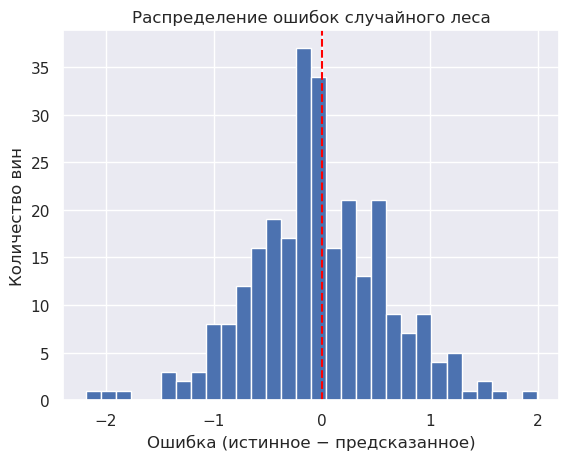

Средняя ошибка: -0.033
Доля вин с ошибкой меньше 0,5: 0.61
Доля вин с ошибкой больше 1:   0.103


In [36]:
errors = y_test - y_pred_rf

plt.hist(errors, bins=30)
plt.axvline(0, color="red", linestyle="--")
plt.title("Распределение ошибок случайного леса")
plt.xlabel("Ошибка (истинное − предсказанное)")
plt.ylabel("Количество вин")
plt.show()

print("Средняя ошибка:", round(errors.mean(), 3))
print("Доля вин с ошибкой меньше 0,5:", round((errors.abs() < 0.5).mean(), 3))
print("Доля вин с ошибкой больше 1:  ", round((errors.abs() > 1).mean(), 3))

### Вывод по распределению ошибок

Средняя ошибка -0,333, почти ноль, то есть систематического сдвига нет. Ошибки распределены равномерно вокруг нуля.

61% вин модель предсказывает точнее чем на полбалла, но у 10% ошибка больше балла. Эти крупные промахи (хвосты гистограммы, до 2) и делают RMSE заметно больше MAE.

      count  mean_pred  mean_error    MAE
true                                     
3         2      5.110      -2.110  2.110
4        11      5.061      -1.061  1.061
5       116      5.358      -0.358  0.369
6       107      5.800       0.200  0.413
7        33      6.295       0.705  0.719
8         3      6.693       1.307  1.307


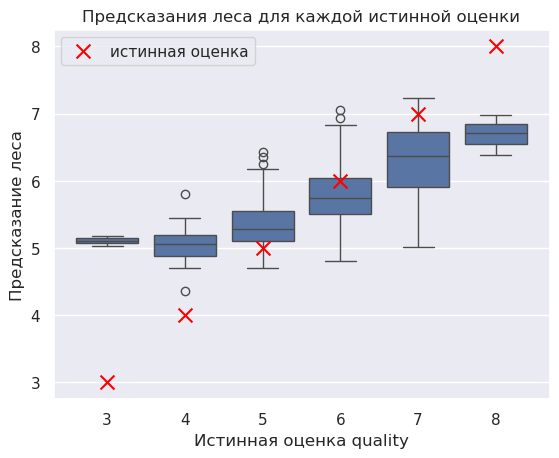

In [37]:
err_df = pd.DataFrame({"true": y_test, "pred": y_pred_rf, "error": errors})

by_quality = err_df.groupby("true").agg(
    count=("error", "size"),
    mean_pred=("pred", "mean"),
    mean_error=("error", "mean"),
    MAE=("error", lambda e: e.abs().mean()),
).round(3)
print(by_quality)

levels = sorted(y_test.unique())
ax = sns.boxplot(x=y_test, y=y_pred_rf)
ax.scatter(range(len(levels)), levels, color="red", marker="x", s=100, zorder=3,
           label="истинная оценка")
ax.set_xlabel("Истинная оценка quality")
ax.set_ylabel("Предсказание леса")
ax.set_title("Предсказания леса для каждой истинной оценки")
ax.legend()
plt.show()

### Вывод по качеству для разных оценок

Модель хорошо работает на частых оценках 5 и 6, но на редких ошибается намного сильнее: у оценки 3 MAE 2,110, у 8 — 1,307.

У оценок 3–5 средняя ошибка отрицательна, то есть модель их завышает, а у 6–8 положительная, то есть модель их занижает. Все предсказания стянуты к середине: истинные оценки от 3 до 8, а предсказания лежат примерно от 5 до 7. Вина с оценками 3 и 4 модель почти не отличает от вин с оценкой 5.

Так происходит, потому что представленно мало примеров. Кроме того, предсказание леса — это усреднение, поэтому редкое вино с оценкой 3, оказывается в одном листе дерева с вином оценкой на 5. И модель минимизирует общую ошибку, а 82% вин имеют оценку 5-6.

В тесте всего 2 вина с оценкой 3 и 3 с оценкой 8, поэтому точные значения MAE для них ненадёжны, но направление ошибки видно по всем крайним оценкам.

In [38]:
key_features = ["alcohol", "volatile acidity", "sulphates"]

worst_idx = err_df["error"].abs().sort_values(ascending=False).index[:8]
worst = err_df.loc[worst_idx].join(X_test.loc[worst_idx, key_features]).round(2)
print("8 вин с самыми большими ошибками:")
print(worst)
print()

medians = X_train.assign(quality=y_train).groupby("quality")[key_features].median().round(2)
print("Медианы главных признаков по оценкам (train):")
print(medians)

8 вин с самыми большими ошибками:
      true  pred  error  alcohol  volatile acidity  sulphates
718      3  5.19  -2.19      9.9              0.44       0.86
1165     3  5.03  -2.03      9.8              0.82       0.51
6        7  5.01   1.99     10.0              0.65       0.47
608      4  5.81  -1.81      9.6              0.38       0.70
434      8  6.39   1.61     11.0              0.35       0.65
1243     7  5.43   1.57     10.0              0.48       0.65
558      7  5.51   1.49     10.1              0.64       0.69
1050     4  5.45  -1.45      9.3              0.23       0.49

Медианы главных признаков по оценкам (train):
         alcohol  volatile acidity  sulphates
quality                                      
3          10.07              0.93       0.55
4          10.05              0.65       0.56
5           9.60              0.59       0.58
6          10.50              0.49       0.64
7          11.55              0.36       0.74
8          12.60              0.39     

### Вывод по самым крупным ошибкам

Среди 8 вин с самыми большими ошибками нет ни одного с оценкой 5 или 6: все они имеют редкие оценки (3, 4, 7, 8). Это подтверждает, что модель чаще ошибается на редких данных.

Например, вино 6 получило оценку 7, а модель предсказала 5,01. Но по главным признакам (alcohol, volatile acidity, sulphates) оно похоже на типичное вино с оценкой 5. Модель следовала признакам, а дегустаторы оценили вино выше по причинам, которых нет в данных

Вино 1165 получило оценку 3. Здесь признаки, наоборот, подсказывают правильный ответ: volatile acidity 0,82 (близко к медиане троек 0,93), sulphates 0,51 (как у 3–4). Но модель всё равно дала 5. Это ошибка из-за редкости оценки: вин на 3 в train всего около 8, и лес стягивает предсказание к середине.


Таким образом, крупные ошибки бывают двух типов: нетипичные вина и на редких оценках.

## Итог

Лучшей моделью оказался случайный лес: RMSE 0,626 и MAE 0,48 на тесте, это на 23,5% лучше baseline, порог 0,70 пройден. Кросс-валидация подтвердила тот же порядок моделей. Главные признаки у всех моделей одинаковые: alcohol, volatile acidity и sulphates.

Основное ограничение — сами данные: оценки субъективны, а вина с редкими оценками (3, 4, 8) встречаются редко и по признакам похожи на соседние. Поэтому модель хорошо работает на оценках 5–6 и сильно ошибается на крайних.